In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import torch

In [29]:

import os
import torch.backends.cudnn as cudnn
import torch
import torchvision
import torch.nn.functional as F
import numpy as np
import pandas as pd
import time
from datetime import datetime 
import pdb
import yaml
import sys
import glob
import shutil
import tqdm
import matplotlib.pyplot as plt
from PIL import Image
import cv2

#from pytorch_grad_cam import GradCAM
#from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
#from pytorch_grad_cam.utils.image import show_cam_on_image
import captum
from captum.attr import IntegratedGradients, Occlusion, LayerGradCam, LayerAttribution, GuidedGradCam
from matplotlib.colors import LinearSegmentedColormap
from captum.attr import visualization as viz



sys.path.append('../../MARS')

from MARS.run_lars.dataset import get_datasets, dataset_center
from MARS.run_lars.utils import model_prediction, my_model


In [3]:
model_path = '/gpfs/data/mayerhoeferlab/projects/lars/lars-avg-max_chpt/LARS_trained_state-dict_0.pth'
data_path_img = '/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/images_h5/'
data_path = '/gpfs/data/mayerhoeferlab/projects/myeloma/datafiles_for_mars/'



In [30]:
df = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/results/run_lars_on_mars/pred_0.csv')

# only use accessions in the train split
split = pd.read_pickle('/gpfs/data/mayerhoeferlab/projects/myeloma/datafiles_for_mars/splits/train_val_test_split.pkl')
df = df[df['accession'].isin(split['train'])]
binarization_threshold = 0.359923 # from LARS

df = df[['accession', 'probs', 'mipview']]

target = pd.read_excel('/gpfs/data/mayerhoeferlab/projects/myeloma/curated_status/Myeloma_master_ref_15_08_2025.xlsx')
target = target.rename(columns={'ACC':'accession','PET-jco':'PET_jco','PET-imwg':'PET_imwg'})
target = target[['accession', 'PET_jco', 'PET_imwg']]

# merge to get labels
merged = pd.merge(df, target[['accession', 'PET_jco', 'PET_imwg']] , on='accession', how='left')
merged = merged[['accession', 'probs', 'PET_jco', 'PET_imwg', 'mipview']]

# exclude cases where there was no label available
merged = merged.dropna(subset = ['PET_jco'], axis='index')

# also exclude cases where the label is 2 (just for now)
merged = merged[merged['PET_jco'] != 2]

merged['difference'] = abs(merged['probs'] - merged['PET_jco'])

/tmp/ipykernel_733413/3877921890.py:1: DtypeWarning: Columns (26) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/results/run_lars_on_mars/pred_0.csv')


In [32]:
merged['binarized_prediction']  = (merged['probs'] >= binarization_threshold).astype(int)
merged = merged[['accession', 'mipview', 'probs', 'binarized_prediction', 'PET_jco', 'PET_imwg']]

In [ ]:
merged = merged.sort_values(by=['accession', 'mipview'])

In [36]:
merged.to_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/results/run_lars_on_mars/pred_0_results_compiled.csv', index=False)

In [ ]:
xd = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/results/run_lars_on_mars/pred_0.csv')
# add columns from xd into merged
tmpo = pd.merge(merged, xd, on=['accession', 'mipview', 'probs'], how='left')

/tmp/ipykernel_733413/769963003.py:1: DtypeWarning: Columns (26) have mixed types. Specify dtype option on import or set low_memory=False.
  xd = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/results/run_lars_on_mars/pred_0.csv')


In [50]:
tmpo.to_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/results/run_lars_on_mars/pred_0_results_compiled_with_additional_info.csv', index=False)

In [10]:
# 4 categories:

# minimized probs - PET_jco:
    # 1. true positive: PET_jco=1
    # 2. true negative: PET_jco=0

# maximized probs - PET_jco:
    # 1. false positive: PET_jco=0
    # 2. false negative PET_jco=1


merged = merged.sort_values(by='difference', ascending=True) # sort by smallest difference first

num_to_select = 5
true_positives = merged[merged['PET_jco'] == 1].head(num_to_select)
true_negatives = merged[merged['PET_jco'] == 0].head(num_to_select)
false_positives = merged[merged['PET_jco'] == 0].tail(num_to_select)
false_negatives = merged[merged['PET_jco'] == 1].tail(num_to_select)



In [22]:
# next, pick examples where the predicted probability was closest to 0.35 (most uncertain)
merged['certainty'] = abs(merged['probs'] - binarization_threshold)
merged = merged.sort_values(by='certainty', ascending=True) # sort by smallest certainty first
most_uncertain = merged.head(10)

# add a column to most_uncertain to indicate the type of example (TP, TN, FP, FN) using probs and PET_jco
most_uncertain['type'] = most_uncertain.apply(lambda row: 'TP' if (row['probs'] >= binarization_threshold and row['PET_jco'] == 1) else ('TN' if (row['probs'] < binarization_threshold and row['PET_jco'] == 0) else ('FP' if (row['probs'] >= binarization_threshold and row['PET_jco'] == 0) else 'FN')), axis=1)

# next, pick random examples
random_examples = merged.sample(n = 10, replace = False, random_state = 2025)
random_examples['type'] = random_examples.apply(lambda row: 'TP' if (row['probs'] >= binarization_threshold and row['PET_jco'] == 1) else ('TN' if (row['probs'] < binarization_threshold and row['PET_jco'] == 0) else ('FP' if (row['probs'] >= binarization_threshold and row['PET_jco'] == 0) else 'FN')), axis=1)



/tmp/ipykernel_733413/183799485.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  most_uncertain['type'] = most_uncertain.apply(lambda row: 'TP' if (row['probs'] >= binarization_threshold and row['PET_jco'] == 1) else ('TN' if (row['probs'] < binarization_threshold and row['PET_jco'] == 0) else ('FP' if (row['probs'] >= binarization_threshold and row['PET_jco'] == 0) else 'FN')), axis=1)


In [13]:
model = model_prediction(model_path)
model.eval()
model.cuda()
dset = get_datasets(True, None, data_path_img = data_path_img, data_path = data_path)

In [14]:
# get the rgb image for dset[0]
def dataset_tensor_to_rgb_img(tensor):
    # tensor should have shape (1, 310, 310)
    nparray = tensor.numpy().squeeze() # (310,310)
    nparray = np.stack((nparray,)*3, axis=2) # (3,310,310) 
    nparray = (nparray - nparray.min()) / (nparray.max() - nparray.min())
    nparray = nparray * 255
    nparray = nparray.astype(np.uint8)
    return nparray

uu = dataset_tensor_to_rgb_img(dset[0])

#rgb_img = np.transpose(rgb_img, (2, 0, 1))
#print(rgb_img.shape)

In [15]:
default_cmap = LinearSegmentedColormap.from_list('custom blue',
                                                 [(0, '#ffffff'),
                                                  (1, '#0000ff')], N=256)

In [16]:
def save_interpretability_for_study(accession_id, mipview, label_number, fig, axs, type='IntegratedGradients', layer_to_iterate = None, device='cuda'):
    pred_label_idx = label_number
    rr = dset.df[(dset.df['accession'] == accession_id) & (dset.df['mipview'] == mipview)]
    idx = rr.index[0]
    assert len(rr) == 1, "accession_id not found or not unique"
    rr = dset[idx] # get the tensor
    rgb_img = dataset_tensor_to_rgb_img(rr) # convert to rgb image
    predprob = merged[(merged['accession'] == accession_id) & (merged['mipview'] == mipview)]['probs'].values[0]
    true_label = merged[(merged['accession'] == accession_id) & (merged['mipview'] == mipview)]['PET_jco'].values[0]

    inp_tensor = rr.view(1, 1, 310, 310).to(device)

    # show rgb_img on axs[0]
    axs[0].imshow(255 - rgb_img)
    axs[0].axis('off')

    cmap = None
    sign = 'all'
    if type == 'IntegratedGradients':
        obj = IntegratedGradients(model)
        attributions = obj.attribute(inp_tensor, target=pred_label_idx, n_steps=200)
        cmap  = default_cmap
        sign = 'positive'
    elif type == 'LayerGradCam':
        obj = LayerGradCam(model, layer_to_iterate)
        attributions = obj.attribute(inp_tensor, target=pred_label_idx)
        print(attributions.shape)
        attributions = LayerAttribution.interpolate(attributions, inp_tensor.shape[2:])
        cmap = default_cmap
        sign='positive'
    elif type == 'GuidedGradCam':
        obj = GuidedGradCam(model, layer_to_iterate)
        attributions = obj.attribute(inp_tensor, target=pred_label_idx)
        cmap = default_cmap
        sign='positive'
    elif type == 'Occlusion':
        obj = Occlusion(model)
        attributions = obj.attribute(inp_tensor, target=pred_label_idx,
                                    sliding_window_shapes=(1, 15, 15), 
                                    strides=(1, 8, 8), 
                                    baselines=0)
        sign = 'all'
    
    attributions = attributions.cpu().detach().squeeze().view((1, 310, 310)).numpy()
    
    fig.suptitle(f'{type} - accession {accession_id}, label={true_label}, explaining {pred_label_idx}, prob {predprob:.2f}')
    bd = viz.visualize_image_attr(
        np.transpose(attributions, (1,2,0)),
        255 - rgb_img,
        method='blended_heat_map',
        cmap=cmap,
        show_colorbar=False,
        sign=sign,
        title='',
        alpha_overlay = 0.7,
        plt_fig_axis=(fig, axs[1]))
    
    return bd

In [25]:
acc_list = []
mipview_list = []
label_list = []
lab_list = []
true_label = []
for i, grp in enumerate([true_positives, true_negatives]):
    # just do it for the predicted label
    acc_list.extend(grp['accession'].tolist())
    mipview_list.extend(grp['mipview'].tolist())
    label_list.extend(grp['probs'].round().astype(int).tolist())
    lab_list.extend(['TP']*len(grp) if i==0 else ['TN']*len(grp))
    true_label.extend(grp['PET_jco'].astype(int).tolist())

for i, grp in enumerate([false_positives, false_negatives]):
    # do it for both labels
    acc_list.extend(grp['accession'].tolist())
    acc_list.extend(grp['accession'].tolist())
    mipview_list.extend(grp['mipview'].tolist())
    mipview_list.extend(grp['mipview'].tolist())
    label_list.extend( (grp['probs'] >= binarization_threshold).astype(int).tolist())
    label_list.extend((grp['probs'] < binarization_threshold).astype(int).tolist())
    lab_list.extend(['FP']*len(grp)*2 if i==0 else ['FN']*len(grp)*2)
    true_label.extend(grp['PET_jco'].astype(int).tolist()*2)

for i, grp in enumerate([most_uncertain, random_examples]):
    # do it for both labels
    acc_list.extend(grp['accession'].tolist())
    acc_list.extend(grp['accession'].tolist())
    mipview_list.extend(grp['mipview'].tolist())
    mipview_list.extend(grp['mipview'].tolist())
    label_list.extend( (grp['probs'] >= binarization_threshold).astype(int).tolist())
    label_list.extend((grp['probs'] < binarization_threshold).astype(int).tolist())
    lab_list.extend(grp['type'].tolist()*2)
    true_label.extend(grp['PET_jco'].astype(int).tolist()*2)

dfo_prep = pd.DataFrame({'accession': acc_list, 'mipview': mipview_list, 'label': label_list, 'type': lab_list, 'true_label': true_label})

In [ ]:
#fig, axs = plt.subplots(1,2)
#jj = save_interpretability_for_study(26181428, 'sag', 1, fig, axs, type='IntegratedGradients', layer_to_iterate=model.features[7][2].conv2, device='cuda')

In [ ]:
save_dir = '/gpfs/data/mayerhoeferlab/projects/myeloma/results/run_lars_on_mars/plots/interpretability/'
for i, row in dfo_prep.iterrows():
    accession_id = row['accession']
    mipview = row['mipview']
    label_number = row['label']
    lab_type = row['type']
    true_label = row['true_label']

    for method in ['IntegratedGradients', 'GuidedGradCam']:
        new_path = os.path.join(save_dir, lab_type, str(accession_id), f'{method}_explain{label_number}_{mipview}.png')
        os.makedirs(os.path.dirname(new_path), exist_ok=True)
        
        fig, axs = plt.subplots(1, 2, figsize = (10,5))

        # show original image
        
        print(f"Processing {accession_id}, label={true_label}, explaining {label_number}, type {lab_type}, method {method}, {mipview}")
        bd = save_interpretability_for_study(accession_id, mipview, label_number, fig, axs, type=method, layer_to_iterate=model.features[7][2].conv2, device='cuda')
        
        #axs[0].grid('off')
        #axs[1].axis('off')
        bd[0].savefig(new_path, dpi=600)


In [14]:
model

layers_0 = [model.features[0]]

layers_4 = [model.features[4][0].conv2, model.features[4][1].conv2, model.features[4][2].conv2]

layers_5 = [model.features[5][0].conv2, model.features[5][1].conv2, model.features[5][2].conv2, model.features[5][3].conv2]

layers_6 = [model.features[6][0].conv2, model.features[6][1].conv2, model.features[6][2].conv2, model.features[6][3].conv2, model.features[6][4].conv2, model.features[6][5].conv2]

layers_7 = [model.features[7][0].conv2, model.features[7][1].conv2, model.features[7][2].conv2]


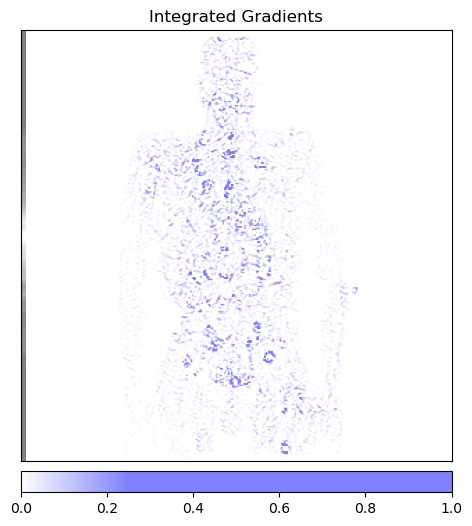

In [35]:
layers_to_iterate = [layers_7[2]]
vv = do_integrated_gradients(16152693, 1, 0.5, layers_to_iterate)

Figure(1000x500)


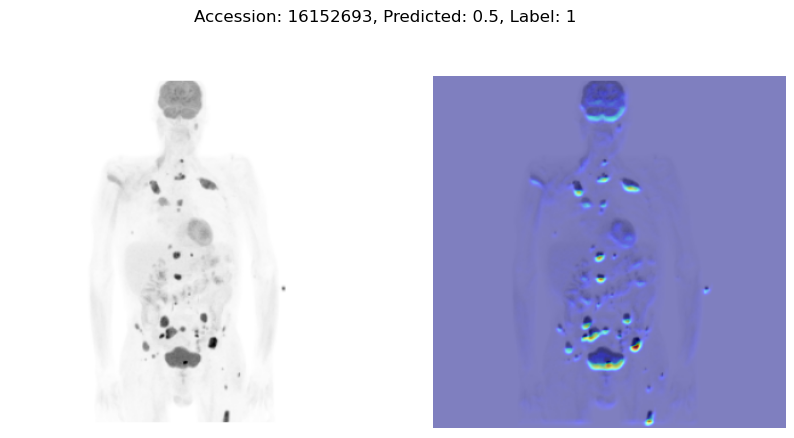

In [178]:
layers_to_iterate = layers_0
do_grad_cam(16152693, 1, 0.5, layers_to_iterate)

Figure(2000x500)


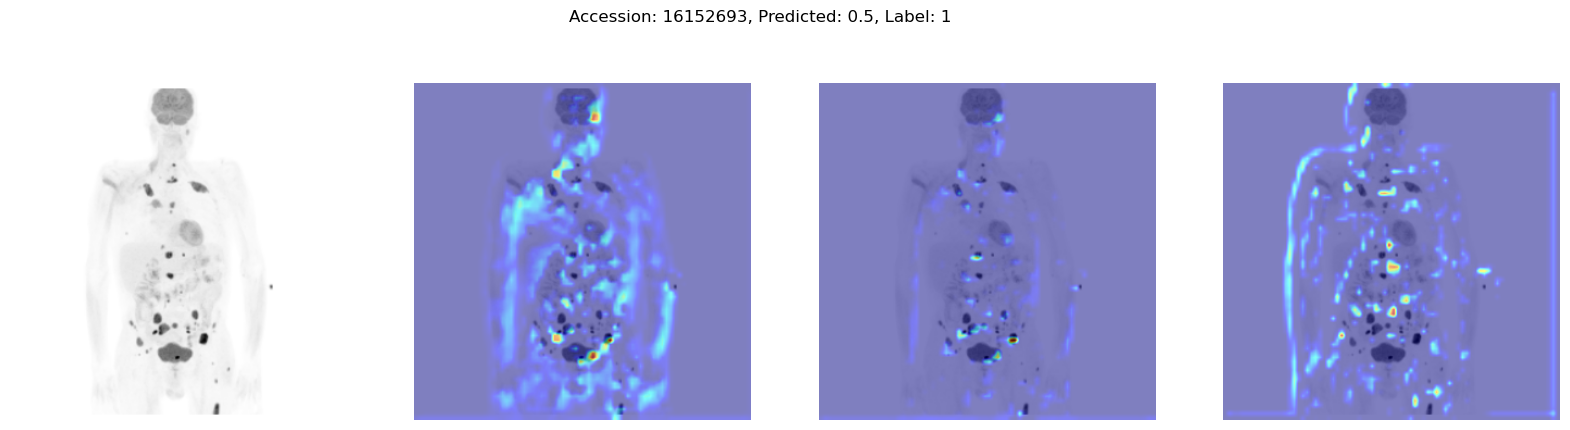

In [179]:
layers_to_iterate = layers_4
do_grad_cam(16152693, 1, 0.5, layers_to_iterate)

Figure(2500x500)


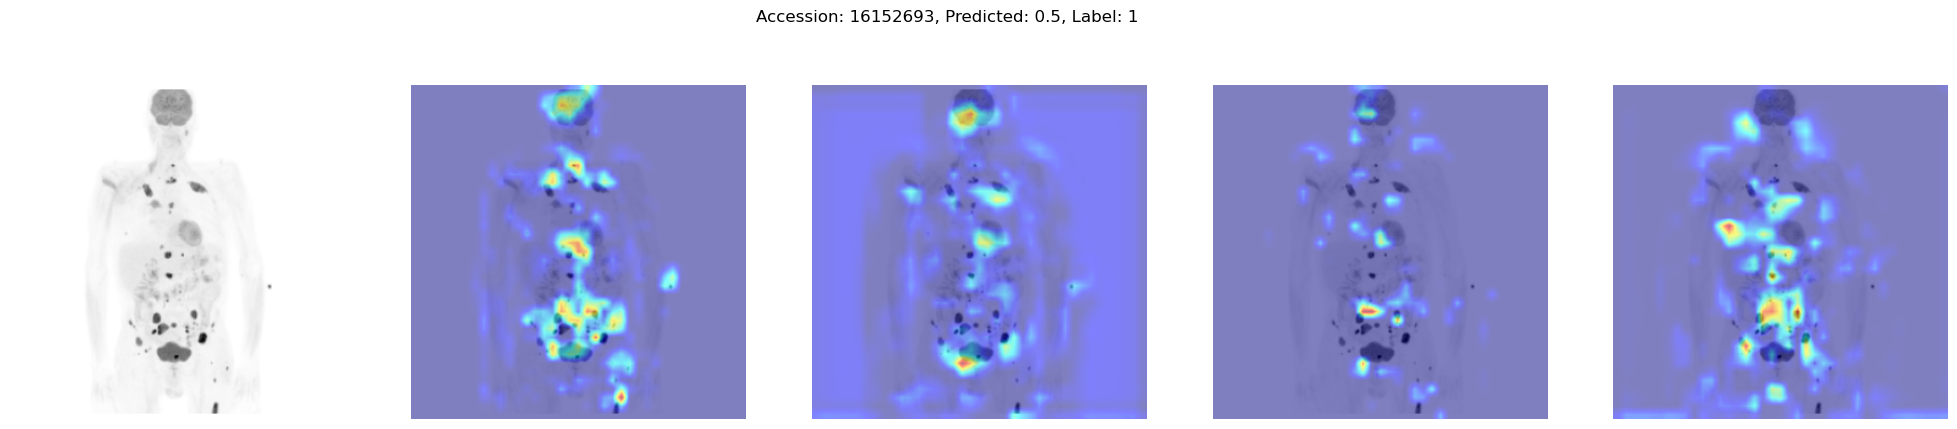

In [180]:
layers_to_iterate = layers_5
do_grad_cam(16152693, 1, 0.5, layers_to_iterate)

Figure(3500x500)


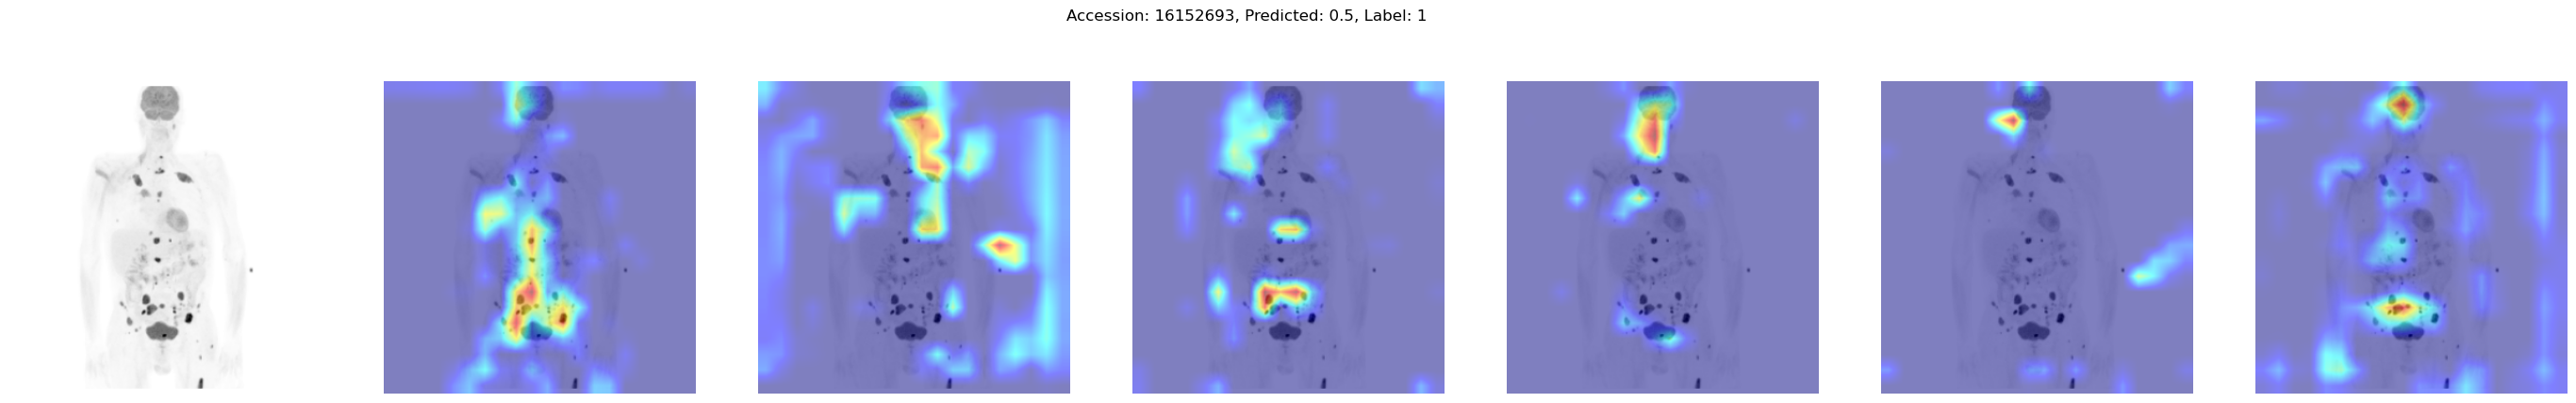

In [181]:
layers_to_iterate = layers_6
do_grad_cam(16152693, 1, 0.5, layers_to_iterate)

In [183]:
true_positives

,accession,probs,PET_jco,PET_imwg,difference
872,15026801,1.0,1,1,0.0
877,15320770,1.0,1,1,0.0
1422,6937014,1.0,1,1,0.0
1411,6510655,1.0,1,1,0.0
146,16152693,1.0,1,1,0.0


Figure(3500x500)


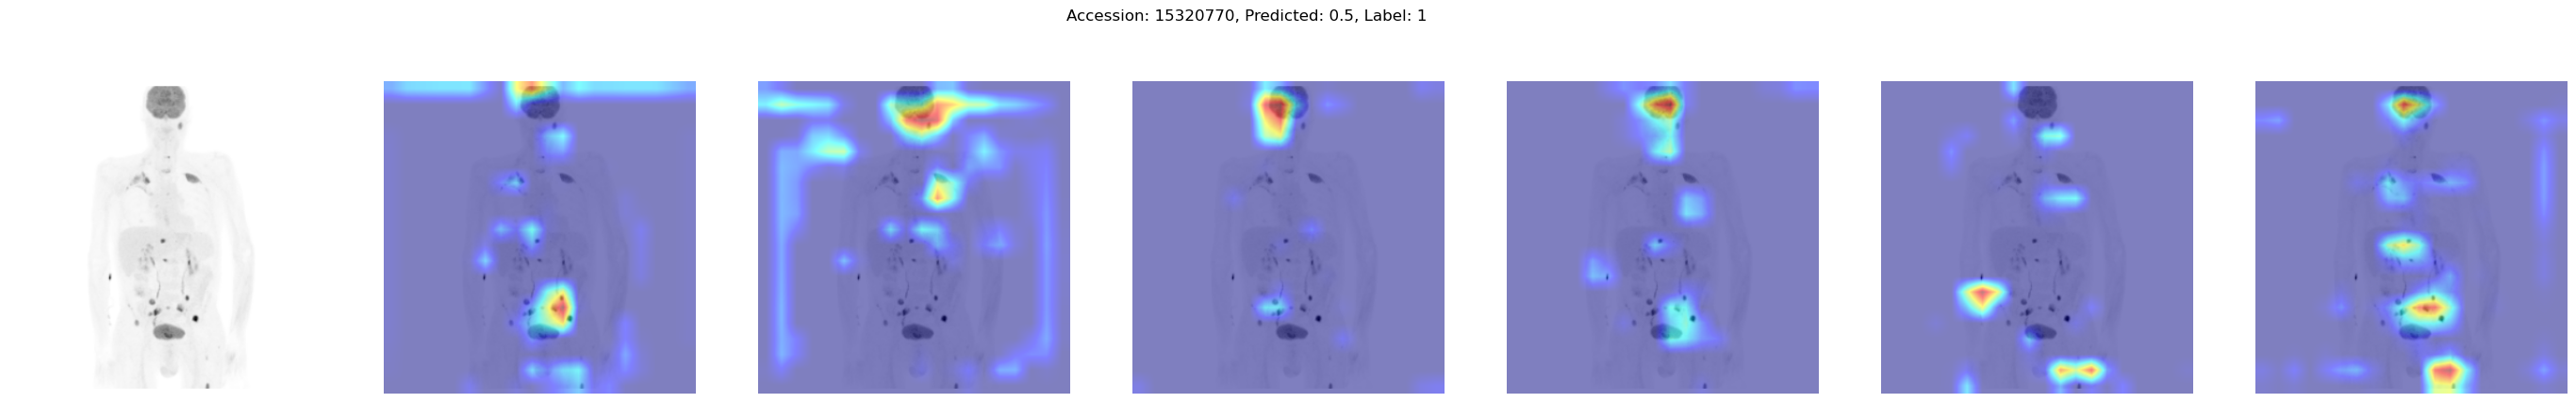

In [200]:
layers_to_iterate = layers_6
do_grad_cam(15320770, 1, 0.5, layers_to_iterate)